# Plant Disease Classifier: Model Comparison

This notebook compares three models trained on 5 PlantVillage classes
(Apple scab, Apple healthy, Potato early blight, Potato healthy, Tomato mosaic virus):

- **Custom CNN**: a small convolutional network trained from scratch
- **MobileNetV2 (frozen)**: pretrained ImageNet base, only the top layers trained
- **MobileNetV2 (aug + weights + fine-tuned)**: adds data augmentation, class weights, and fine-tuning

All models use the same 80/20 train/validation split (seed 123).

In [12]:
import pandas as pd

comparison = pd.concat([
    pd.read_csv("custom_cnn_results.csv"),
    pd.read_csv("mobilenet_frozen_results.csv"),
    pd.read_csv("mobilenet_final_results.csv"),
], ignore_index=True)

comparison = comparison.round(4)
comparison

,Model,Val acc,Val loss,Best val acc,Macro F1
0,Custum CNN,0.9539,0.1718,0.9645,0.9432
1,MobileNetV2 (frozen),0.9329,0.1916,0.9474,0.9120
2,MobileNetV2 (aug + weights),0.9921,0.0209,0.9930,0.9874


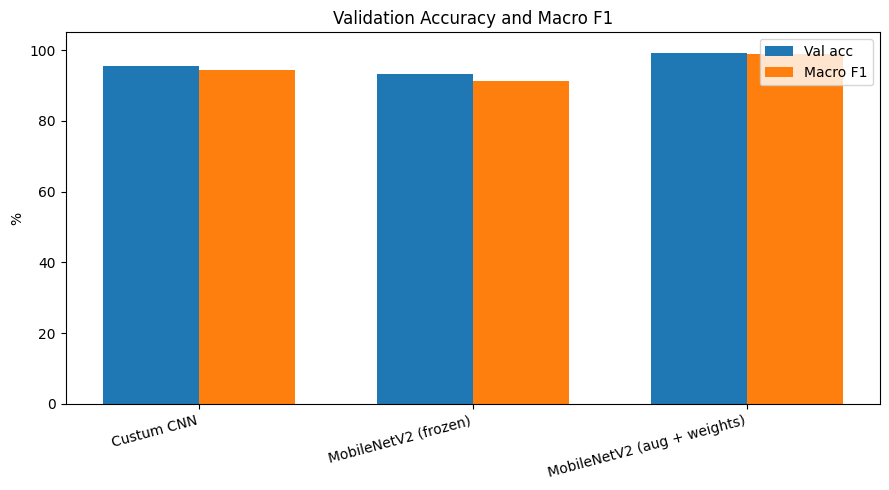

In [13]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(comparison))
w = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - w/2, comparison["Val acc"] * 100, w, label="Val acc")
plt.bar(x + w/2, comparison["Macro F1"] * 100, w, label="Macro F1")
plt.xticks(x, comparison["Model"], rotation=15, ha="right")
plt.ylabel("%")
plt.ylim(0, 105)
plt.title("Validation Accuracy and Macro F1")
plt.legend()
plt.tight_layout()
plt.show()


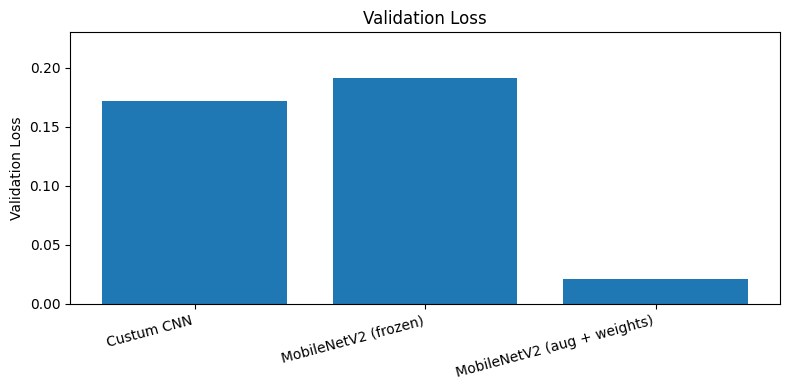

In [14]:

plt.figure(figsize=(8, 4))
plt.bar(comparison["Model"], comparison["Val loss"])
plt.ylim(0, comparison["Val loss"].max() * 1.2)
plt.ylabel("Validation Loss")
plt.title("Validation Loss")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [15]:
best = comparison.loc[comparison["Val acc"].idxmax()]
print("Highest validation accuracy:", best["Model"], round(best["Val acc"] * 100, 2), "%")

Highest validation accuracy: MobileNetV2 (aug + weights) 99.21 %


## Comparison Summary

| Model | Val Accuracy | Macro F1 | Val Loss |
|---|---|---|---|
| Custom CNN | 95.39% | 0.943 | 0.172 |
| MobileNetV2 (frozen) | 93.29% | 0.912 | 0.192 |
| MobileNetV2 (aug + weights ) | 99.21% | 0.987 | 0.021 |

- The improved MobileNetV2 had the highest accuracy and macro F1 and the lowest loss.
- The frozen MobileNetV2 scored lower than the custom CNN. A frozen ImageNet
  backbone did not help on its own for this dataset.
- The improved model combines augmentation and class weights which
  were changed together, so this experiment cannot say which change mattered most.

## Limitations

- Only 5 classes from PlantVillage were used.
- PlantVillage has clean backgrounds and near-duplicate photos of the same leaf,
  so validation accuracy is likely higher than real-world accuracy.
- Results come from one validation split and one training run per model, with no
  separate test set.
- Performance on real-world photos (different backgrounds and lighting) was not evaluated.